# BigBrain gray matter / white matter marker dot plot

Top-10 weighted ensemble와 단일 최적 후보의 영역별 발현을 비교합니다. 유전자들은 해당 영역에만 특이적인 유전자가 아니라 신경세포, 희소돌기아교세포 및 기타 세포의 표지자로, 세포 구성에 따른 해부학적 일관성을 탐색합니다. MOG/MOBP/CLDN11은 myelin/oligodendrocyte, SLC17A7/SYT1/CAMK2A와 GAD1/GAD2는 신경세포 표지자입니다. 측정 패널에 없는 MBP, PLP1, SNAP25 등은 제외했습니다.

전체 1,000개 측정 유전자의 세포별 count 합으로 10,000에 정규화한 뒤 log1p를 적용합니다. 점 크기는 원본 count > 0인 세포 비율, 색은 전체 세포의 평균 log1p 정규화 발현량입니다. 대상 영역 밖 레이블은 제외하되 count가 0인 세포는 포함합니다. 표적 유전자 패널, 세포 조성·검출률·공간 혼합의 영향이 있으며 단일 샘플에 대한 탐색적 비교이므로 정합의 독립적인 증거가 아닙니다.

Cells: 137,627; zero-panel-count cells: 6,893
Expression: log1p(count / total counts across all 1,000 panel genes × 10,000).
Dot size: fraction with raw count > 0; color: mean log-normalized expression across all cells.

Top-10 ensemble: excluded non-GM/WM labels = 0
  Gray matter: 26,410 cells
  White matter: 111,217 cells

Best candidate: excluded non-GM/WM labels = 0
  Gray matter: 31,315 cells
  White matter: 106,312 cells


/home/Data_Drive_8TB/kykim/.conda/envs/scrna/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


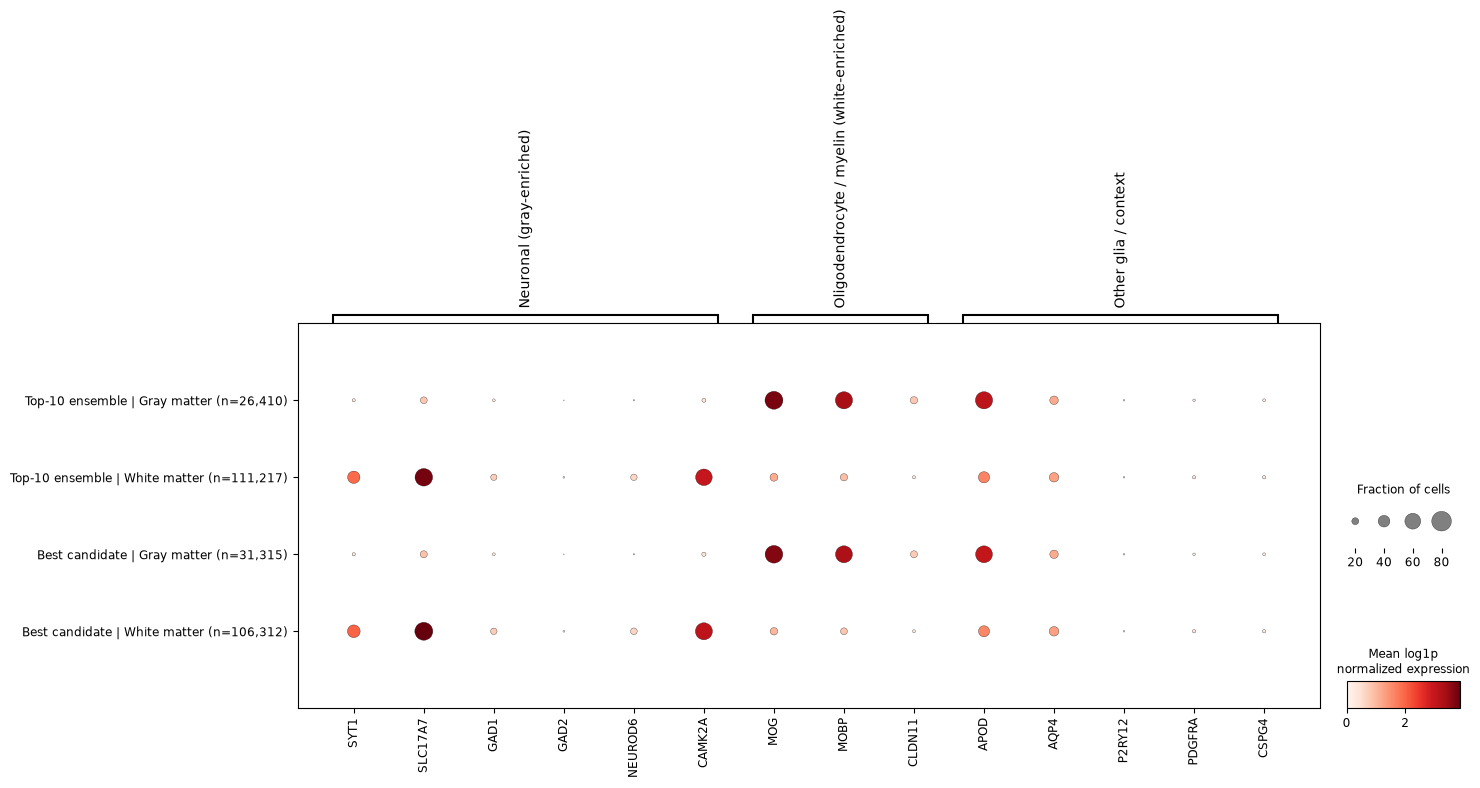

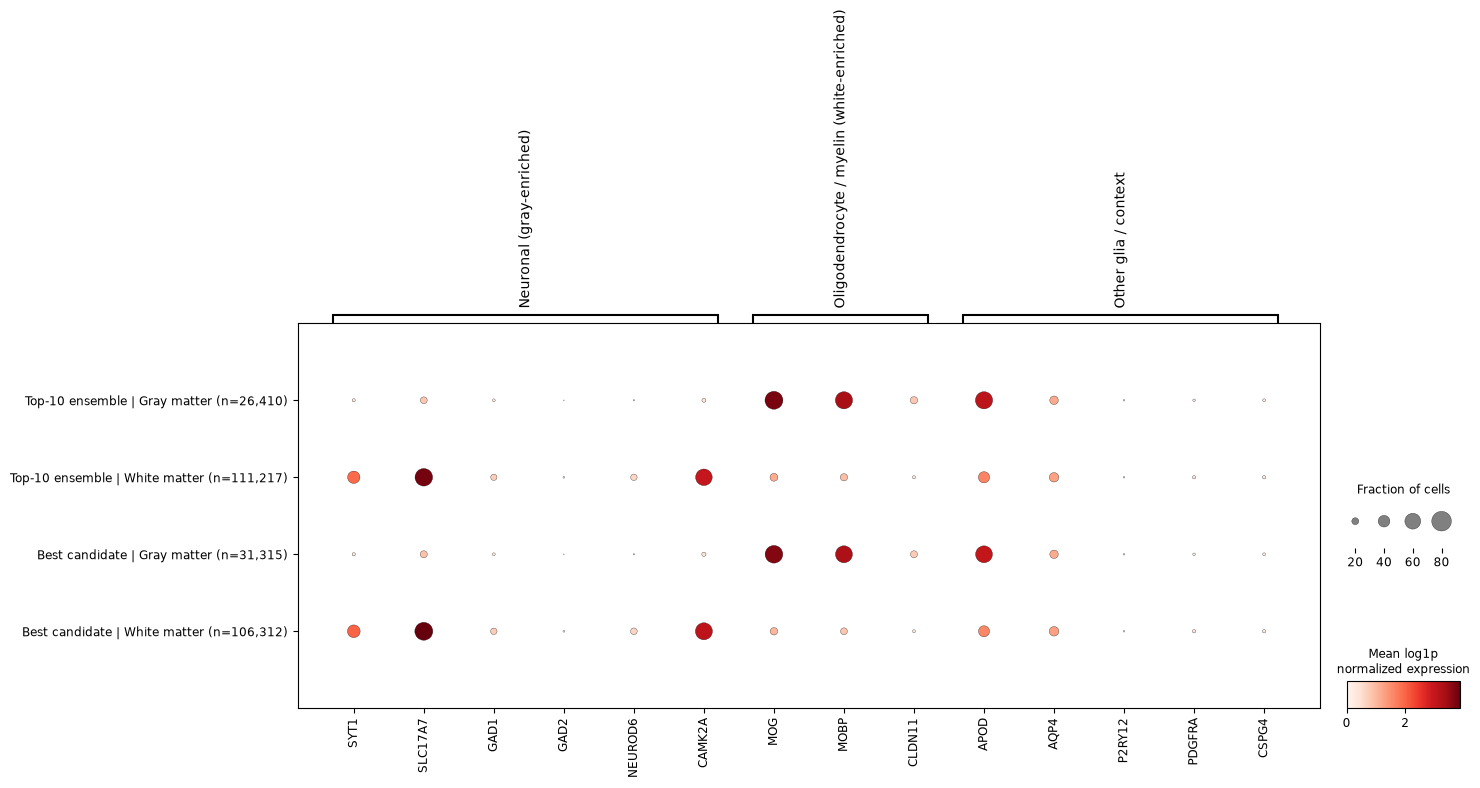

gene                                  CAMK2A   MOBP    MOG  SLC17A7
method          region       n_cells                               
Best candidate  Gray matter  31315     0.103  0.656  0.694    0.205
                White matter 106312    0.661  0.197  0.219    0.709
Top-10 ensemble Gray matter  26410     0.095  0.669  0.709    0.195
                White matter 111217    0.638  0.214  0.237    0.689

Markers reflect cell populations and are not exclusive anatomical region markers.
This is an exploratory consistency check, not independent proof of spatial registration.


In [1]:
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from IPython.display import display

data_path = Path("/home/Data_Drive_8TB/kykim/CCF_annotation/adata.h5ad")
output_dir = Path("/home/Data_Drive_8TB/kykim/0. Jupyter/CCF")
marker_groups = {
    "Neuronal (gray-enriched)": ["SYT1", "SLC17A7", "GAD1", "GAD2", "NEUROD6", "CAMK2A"],
    "Oligodendrocyte / myelin (white-enriched)": ["MOG", "MOBP", "CLDN11"],
    "Other glia / context": ["APOD", "AQP4", "P2RY12", "PDGFRA", "CSPG4"],
}
markers = [gene for group in marker_groups.values() for gene in group]
regions = ["Gray matter", "White matter"]
assignment_files = {
    "Top-10 ensemble": ("BigBrain_top10_consensus_cell_annotation.csv", "ensemble_region"),
    "Best candidate": ("BigBrain_best_cell_annotation.csv", "bigbrain_region"),
}

source = sc.read_h5ad(data_path, backed="r")
try:
    if not source.obs_names.is_unique or not source.var_names.is_unique:
        raise ValueError("Cell IDs and gene names must be unique.")
    missing = [gene for gene in markers if gene not in source.var_names]
    if missing:
        raise ValueError(f"Marker genes not present in the panel: {missing}")
    gene_index = source.var_names.get_indexer(markers)
    labels = {}
    for method, (filename, region_column) in assignment_files.items():
        table = pd.read_csv(output_dir / filename, dtype={"cell_id": str})
        if table["cell_id"].duplicated().any():
            raise ValueError(f"{filename} contains duplicate cell IDs.")
        table = table.set_index("cell_id")
        missing_ids = source.obs_names.difference(table.index)
        extra_ids = table.index.difference(source.obs_names)
        if len(missing_ids) or len(extra_ids):
            raise ValueError(f"{filename}: {len(missing_ids)} missing and {len(extra_ids)} extra cell IDs.")
        label = table.reindex(source.obs_names)[region_column]
        if label.isna().any():
            raise ValueError(f"{filename} contains missing region assignments.")
        labels[method] = label

    counts = np.empty((source.n_obs, len(markers)), dtype=np.float32)
    panel_totals = np.empty(source.n_obs, dtype=np.float64)
    for start in range(0, source.n_obs, 4096):
        stop = min(start + 4096, source.n_obs)
        block = source.X[start:stop]
        if hasattr(block, "toarray"):
            block = block.toarray()
        block = np.asarray(block)
        if not np.isfinite(block).all() or (block < 0).any() or not np.equal(block, np.floor(block)).all():
            raise ValueError("Expected finite nonnegative integer transcript counts in adata.X.")
        counts[start:stop] = block[:, gene_index]
        panel_totals[start:stop] = block.sum(axis=1, dtype=np.float64)
    cell_ids = source.obs_names.copy()
finally:
    source.file.close()

log_expression = np.zeros_like(counts)
nonzero = panel_totals > 0
log_expression[nonzero] = np.log1p(
    counts[nonzero] * (10_000 / panel_totals[nonzero, None])
)
print(f"Cells: {len(cell_ids):,}; zero-panel-count cells: {(~nonzero).sum():,}")
print("Expression: log1p(count / total counts across all 1,000 panel genes × 10,000).")
print("Dot size: fraction with raw count > 0; color: mean log-normalized expression across all cells.")

plot_values, plot_groups, summary = [], [], []
for method, label in labels.items():
    excluded = ~label.isin(regions)
    print(f"\n{method}: excluded non-GM/WM labels = {excluded.sum():,}")
    for region in regions:
        mask = label.eq(region).to_numpy()
        n = int(mask.sum())
        if not n:
            raise ValueError(f"{method} has no cells assigned to {region}.")
        print(f"  {region}: {n:,} cells")
        group_name = f"{method} | {region} (n={n:,})"
        plot_values.append(log_expression[mask])
        plot_groups.extend([group_name] * n)
        fraction = (counts[mask] > 0).mean(axis=0)
        mean = log_expression[mask].mean(axis=0)
        summary.extend(
            {"method": method, "region": region, "n_cells": n, "gene": gene,
             "fraction_expressing": float(frac), "mean_log1p_normalized": float(avg)}
            for gene, frac, avg in zip(markers, fraction, mean)
        )

group_order = list(dict.fromkeys(plot_groups))
plot_data = ad.AnnData(
    X=np.concatenate(plot_values),
    obs=pd.DataFrame({"assignment": pd.Categorical(plot_groups, categories=group_order, ordered=True)}),
    var=pd.DataFrame(index=pd.Index(markers, name="gene")),
)
dot = sc.pl.dotplot(
    plot_data, marker_groups, groupby="assignment", use_raw=False,
    expression_cutoff=0, mean_only_expressed=False, standard_scale=None,
    cmap="Reds", vmin=0, figsize=(15, 5), return_fig=True,
)
dot.legend(colorbar_title="Mean log1p\nnormalized expression", size_title="Fraction of cells")
dot.make_figure()
dot.savefig(output_dir / "BigBrain_gray_white_marker_dotplot.png", dpi=180, bbox_inches="tight")
plt.show()

summary_df = pd.DataFrame(summary)
summary_df.to_csv(output_dir / "BigBrain_gray_white_marker_dotplot_values.csv", index=False)
display(summary_df[summary_df["gene"].isin(["SLC17A7", "CAMK2A", "MOG", "MOBP"])]
        .pivot(index=["method", "region", "n_cells"], columns="gene", values="fraction_expressing")
        .round(3))
print("Markers reflect cell populations and are not exclusive anatomical region markers.")
print("This is an exploratory consistency check, not independent proof of spatial registration.")
